In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("appointments.csv")
print("Raw Dataset Shape:", df.shape)
print("\nAppointment Status Breakdown:\n", df["status"].value_counts())

Raw Dataset Shape: (111488, 16)

Appointment Status Breakdown:
 status
attended          86032
cancelled         18254
did not attend     6615
unknown             446
scheduled           141
Name: count, dtype: int64


In [3]:
df_att = df[df["status"] == "attended"].copy()

def time_to_seconds(t_str):
    h, m, s = map(int, str(t_str).split(":"))
    return h * 3600 + m * 60 + s

df_att["checkin_sec"] = df_att["check_in_time"].apply(time_to_seconds)
df_att["appt_sec"] = df_att["appointment_time"].apply(time_to_seconds)
df_att["start_sec"] = df_att["start_time"].apply(time_to_seconds)
df_att["end_sec"] = df_att["end_time"].apply(time_to_seconds)

df_att = df_att.sort_values(["appointment_date", "checkin_sec"]).reset_index(drop=True)
print("Valid Attended Visits:", len(df_att))
df_att[["appointment_date", "check_in_time", "start_time", "appointment_duration", "waiting_time"]].head()

Valid Attended Visits: 86032


,appointment_date,check_in_time,start_time,appointment_duration,waiting_time
0,2015-01-01,08:02:35,08:03:41,2.6,1.1
1,2015-01-01,08:21:07,08:22:11,16.0,1.1
2,2015-01-01,08:34:23,08:39:07,17.7,4.7
3,2015-01-01,08:59:55,09:00:48,22.3,0.9
4,2015-01-01,09:10:58,09:24:02,6.6,13.1


In [4]:
n = len(df_att)
patients_ahead = np.zeros(n, dtype=int)
in_consult = np.zeros(n, dtype=int)
elapsed_in_room = np.zeros(n, dtype=float)
prev_avg_dur = np.full(n, 17.5)

for _, grp in df_att.groupby("appointment_date", sort=False):
    idxs = grp.index.values
    c_sec = grp["checkin_sec"].values
    s_sec = grp["start_sec"].values
    e_sec = grp["end_sec"].values
    durs = grp["appointment_duration"].values

    for k in range(1, len(idxs)):
        waiting_before = np.sum(s_sec[:k] > c_sec[k])
        inside_mask = (s_sec[:k] <= c_sec[k]) & (e_sec[:k] > c_sec[k])
        currently_inside = int(np.sum(inside_mask))

        patients_ahead[idxs[k]] = waiting_before + currently_inside
        in_consult[idxs[k]] = currently_inside

        if currently_inside > 0:
            elapsed_in_room[idxs[k]] = np.max(c_sec[k] - s_sec[:k][inside_mask]) / 60.0

        completed_mask = e_sec[:k] <= c_sec[k]
        if np.any(completed_mask):
            prev_avg_dur[idxs[k]] = np.mean(durs[:k][completed_mask])

df_att["queue_position"] = patients_ahead
df_att["in_consult"] = in_consult
df_att["elapsed_in_room"] = elapsed_in_room
df_att["prev_avg_dur"] = prev_avg_dur
df_att["checkin_hour"] = df_att["checkin_sec"] / 3600.0
df_att["arrival_offset_mins"] = (df_att["checkin_sec"] - df_att["appt_sec"]) / 60.0
df_att["day_of_week"] = pd.to_datetime(df_att["appointment_date"]).dt.dayofweek

FEATURE_COLS = [
    "queue_position",
    "in_consult",
    "elapsed_in_room",
    "prev_avg_dur",
    "checkin_hour",
    "arrival_offset_mins",
    "day_of_week",
    "age",
    "scheduling_interval",
]

df_att[FEATURE_COLS + ["waiting_time"]].head()

,queue_position,in_consult,elapsed_in_room,prev_avg_dur,checkin_hour,arrival_offset_mins,day_of_week,age,scheduling_interval,waiting_time
0,0,0,0.000000,17.5,8.043056,-12.416667,3,65,5,1.1
1,0,0,0.000000,2.6,8.351944,-8.883333,3,45,1,1.1
2,1,1,12.200000,2.6,8.573056,-10.616667,3,40,5,4.7
3,0,0,0.000000,12.1,8.998611,-0.083333,3,90,6,0.9
4,1,1,10.166667,12.1,9.182778,-19.033333,3,83,4,13.1


In [5]:
# Chronological 80/20 split so past dates train the model and future dates test it
split_idx = int(len(df_att) * 0.80)

X_train = df_att[FEATURE_COLS].iloc[:split_idx]
y_train = df_att["waiting_time"].iloc[:split_idx]
X_test = df_att[FEATURE_COLS].iloc[split_idx:]
y_test = df_att["waiting_time"].iloc[split_idx:]

# 1. Simple Queue-Based Baseline (Queue Position * Historical Mean Duration 17.5 mins)
avg_consult_time = y_train.index.map(lambda _: df_att["appointment_duration"].iloc[:split_idx].mean())[0]
baseline_preds = X_test["queue_position"] * avg_consult_time

# 2. HistGradientBoosting Regressor
gb_model = HistGradientBoostingRegressor(max_iter=250, learning_rate=0.08, max_depth=8, random_state=42)
gb_model.fit(X_train, y_train)
gb_preds = np.clip(gb_model.predict(X_test), 0, None)

# 3. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, max_depth=14, n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = np.clip(rf_model.predict(X_test), 0, None)

def eval_regressor(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "MAE (mins)": round(mae, 2), "RMSE (mins)": round(rmse, 2), "R2 Score": round(r2, 4)}

eval_df = pd.DataFrame([
    eval_regressor(y_test, baseline_preds, "Queue-Based Baseline (RQ3)"),
    eval_regressor(y_test, rf_preds, "Random Forest Regressor"),
    eval_regressor(y_test, gb_preds, "Gradient Boosting Regressor"),
])

eval_df

,Model,MAE (mins),RMSE (mins),R2 Score
0,Queue-Based Baseline (RQ3),12.68,17.44,0.8222
1,Random Forest Regressor,11.92,17.12,0.8288
2,Gradient Boosting Regressor,11.95,17.03,0.8305


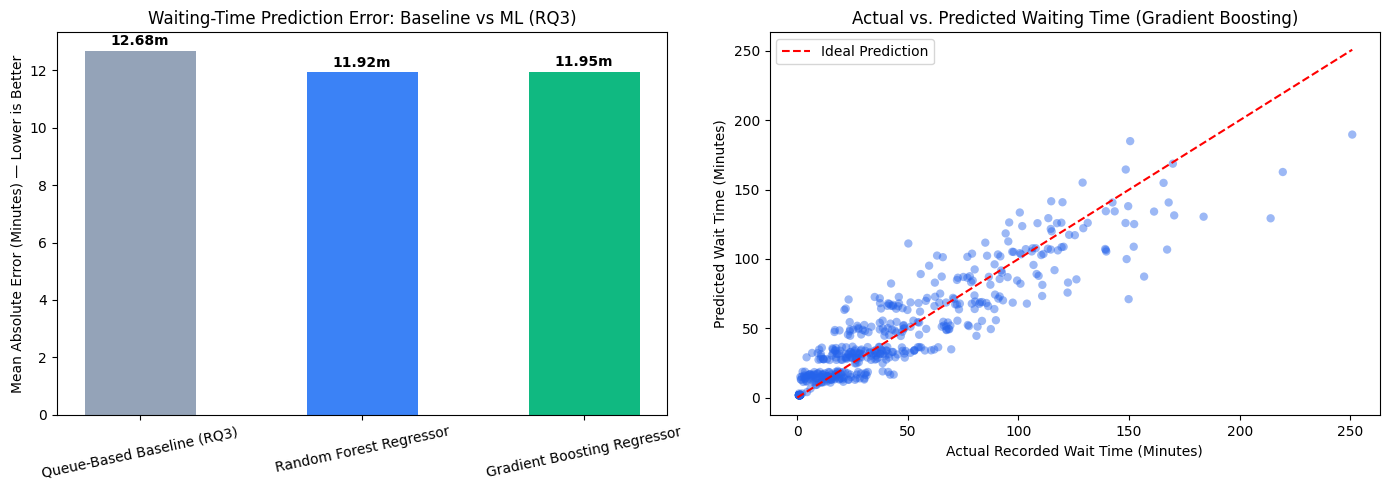

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: MAE Comparison (Lower is Better)
colors = ["#94a3b8", "#3b82f6", "#10b981"]
bars = axes[0].bar(eval_df["Model"], eval_df["MAE (mins)"], color=colors, width=0.5)
axes[0].set_title("Waiting-Time Prediction Error: Baseline vs ML (RQ3)")
axes[0].set_ylabel("Mean Absolute Error (Minutes) — Lower is Better")
axes[0].tick_params(axis="x", rotation=12)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.2, f"{h:.2f}m", ha="center", fontweight="bold")

# Chart 2: Actual vs Predicted Wait Time (Sample of 500 Test Visits)
sample_idx = np.random.RandomState(42).choice(len(y_test), size=500, replace=False)
axes[1].scatter(y_test.iloc[sample_idx], gb_preds[sample_idx], alpha=0.45, color="#2563eb", edgecolors="none")
max_val = max(y_test.iloc[sample_idx].max(), gb_preds[sample_idx].max())
axes[1].plot([0, max_val], [0, max_val], "r--", linewidth=1.5, label="Ideal Prediction")
axes[1].set_title("Actual vs. Predicted Waiting Time (Gradient Boosting)")
axes[1].set_xlabel("Actual Recorded Wait Time (Minutes)")
axes[1].set_ylabel("Predicted Wait Time (Minutes)")
axes[1].legend()

plt.tight_layout()
plt.savefig("waittime_evaluation_charts.png", dpi=300)
plt.show()

In [7]:
def predict_wait_time(queue_position, in_consult=1, elapsed_in_room=5.0, prev_avg_dur=17.5, checkin_hour=10.5, age=42):
    row = pd.DataFrame([{
        "queue_position": queue_position,
        "in_consult": in_consult,
        "elapsed_in_room": elapsed_in_room,
        "prev_avg_dur": prev_avg_dur,
        "checkin_hour": checkin_hour,
        "arrival_offset_mins": -5.0,
        "day_of_week": 2,
        "age": age,
        "scheduling_interval": 7,
    }])
    est_mins = float(np.clip(gb_model.predict(row)[0], 1.0, None))
    return round(est_mins, 1)

print("Sample Prediction (Queue Position #3):", predict_wait_time(queue_position=3), "mins")

joblib.dump(
    {
        "waittime_model": gb_model,
        "feature_cols": FEATURE_COLS,
        "default_avg_dur": round(float(avg_consult_time), 2),
    },
    "waittime_model_bundle.joblib",
)
print("Exported waittime_model_bundle.joblib successfully!")

Sample Prediction (Queue Position #3): 51.6 mins
Exported waittime_model_bundle.joblib successfully!


In [8]:
clean_cols = [
    "appointment_id", "patient_id", "appointment_date", "appointment_time",
    "check_in_time", "start_time", "end_time", "sex", "age", "age_group",
    "scheduling_interval", "appointment_duration",
    "queue_position", "in_consult", "elapsed_in_room", "prev_avg_dur",
    "checkin_hour", "arrival_offset_mins", "day_of_week", "waiting_time"
]

df_att[clean_cols].to_csv("cleaned_appointments.csv", index=False)
print("Saved cleaned_appointments.csv:", df_att[clean_cols].shape)

Saved cleaned_appointments.csv: (86032, 20)
